# Lab 1 · Part 3 — Draw on Camera Frames with OpenCV

**Goal:** Draw simple shapes and text on images from the JetRacer CSI camera.


In this exercise, you will:

1. Get a frame from the wide CSI camera.
2. Draw a line, a rectangle, a circle, and text.
3. Add guide lines to the live camera view.
4. Change a guide line with a slider.


## 1. Prepare the camera

1. Finish Lab 1, Part 2. Press **STOP CAR** and **Stop Camera**.
2. Shut down the Part 2 notebook kernel. Only one program can use the CSI camera at a time.
3. Open this notebook on the Jetson Nano.
4. Keep the car stationary. This exercise does not use the motors.

Use the same wide camera settings as Part 2:

```python
CSICamera(
    width=640,
    height=360,
    capture_width=1280,
    capture_height=720,
    capture_fps=30
)
```

We will keep these settings for the next labs.

## 2. Image coordinates and colors

OpenCV works with pixels. Each pixel has a position `(x, y)`.

- `x` increases from left to right.
- `y` increases from top to bottom.
- The top-left pixel is `(0, 0)`.
- The bottom-right pixel is `(639, 359)` in our 640 × 360 image.

OpenCV uses **BGR** color order for JetCam frames:

| Color | BGR value |
| --- | --- |
| Blue | `(255, 0, 0)` |
| Green | `(0, 255, 0)` |
| Red | `(0, 0, 255)` |
| Yellow | `(0, 255, 255)` |

For example, `cv2.line(image, point_1, point_2, color, thickness)` draws a line. `thickness` is in pixels.

## 3. Start the wide camera

The live view starts with **no drawings**. Use **Start Camera** to open the camera.

- **Start Camera** opens the camera and sets `camera.running = True`.
- **Stop Camera** stops capture and releases the device.
- You can start the camera again after you stop it.

Keep this cell small. We only need a camera, a preview, and two buttons.

### Open the camera and capture one image

In [7]:
import cv2
import ipywidgets as widgets
from IPython.display import display, Image
from jetcam.csi_camera import CSICamera
camera = CSICamera(
    width=640,
    height=360,
    capture_width=1280,
    capture_height=720,
    capture_fps=30
)

frame = camera.read()
camera.cap.release()

Image size: (360, 640, 3)


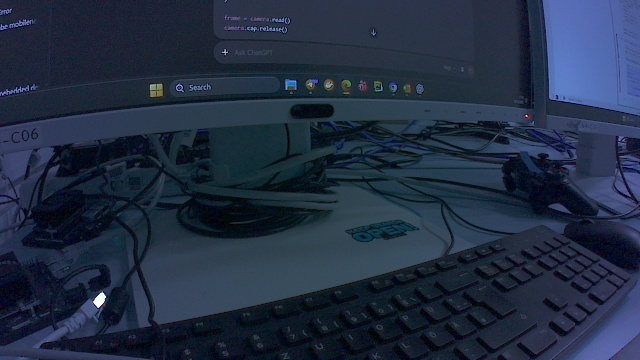

In [8]:
print("Image size:", frame.shape)

# Convert RGB to JPEG-compatible BGR
bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

display(Image(data=cv2.imencode('.jpg', bgr)[1].tobytes()))

### Draw a horizontal line

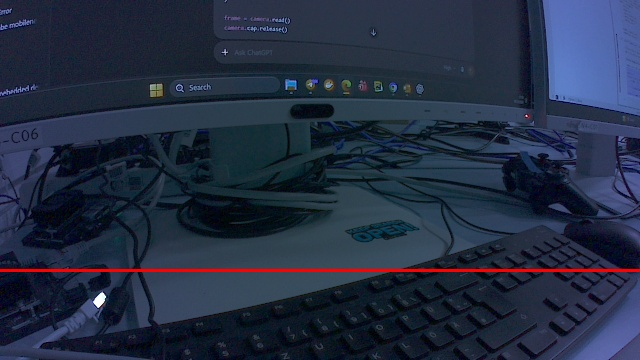

In [12]:
image = frame.copy()

cv2.line(
    image,
    (0, 270),       # Start point (x, y)
    (639, 270),     # End point (x, y)
    (255, 0, 0),    # Red (RGB)
    2               # Thickness
)
bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
display(Image(data=cv2.imencode('.jpg', bgr)[1].tobytes()))

### Draw vertical line

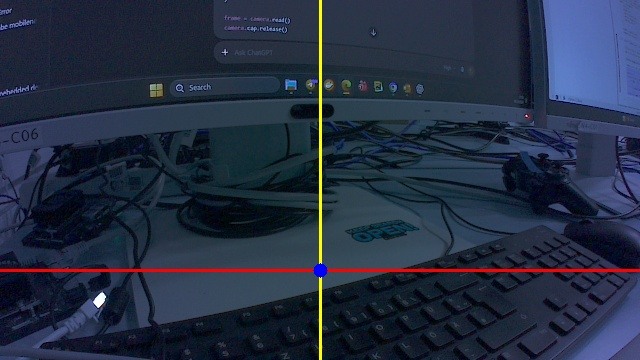

In [13]:
# Vertical line
cv2.line(image, (320, 0), (320, 359), (255, 255, 0), 2)

# Filled circle
cv2.circle(image, (320, 270), 7, (0, 0, 255), -1)

bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
display(Image(data=cv2.imencode('.jpg', bgr)[1].tobytes()))

### Putting all together

In [14]:


camera = None
frame_number = 0

start_button = widgets.Button(description='Start Camera', button_style='success')
stop_button = widgets.Button(description='Stop Camera', button_style='warning', disabled=True)
status = widgets.HTML(value='<b>Camera:</b> Stopped')
preview = widgets.Image(format='jpeg', width=640, height=360)

show_guides = widgets.Checkbox(value=False, description='Show guide lines')
line_y = widgets.IntSlider(
    value=270, min=0, max=359, step=5,
    description='Line Y', continuous_update=False
)


def update_preview(change):
    global frame_number
    frame_number += 1
    if frame_number % 3 != 0:
        return  # Update the notebook display less often.

    image = change['new'].copy()
    if show_guides.value:
        cv2.line(image, (0, line_y.value), (639, line_y.value), (0, 0, 255), 2)
        cv2.line(image, (320, 0), (320, 359), (0, 255, 255), 2)
        cv2.circle(image, (320, line_y.value), 7, (255, 0, 0), -1)

    ok, jpg = cv2.imencode('.jpg', image)
    if ok:
        preview.value = jpg.tobytes()


def start_camera(button):
    global camera, frame_number
    if camera is not None:
        return

    start_button.disabled = True
    status.value = '<b>Camera:</b> Opening...'
    frame_number = 0

    try:
        camera = CSICamera(
            width=640, height=360,
            capture_width=1280, capture_height=720,
            capture_fps=30
        )
        camera.observe(update_preview, names='value')
        camera.running = True
        stop_button.disabled = False
        status.value = '<b>Camera:</b> Running (640 x 360)'
    except Exception as error:
        if camera is not None:
            camera.running = False
            camera.cap.release()
        camera = None
        start_button.disabled = False
        status.value = '<b>Camera:</b> Error: ' + str(error)


def stop_camera(button):
    global camera
    if camera is not None:
        camera.running = False
        camera.unobserve(update_preview, names='value')
        camera.cap.release()
        camera = None

    preview.value = b''
    start_button.disabled = False
    stop_button.disabled = True
    status.value = '<b>Camera:</b> Stopped and released'


start_button.on_click(start_camera)
stop_button.on_click(stop_camera)

display(widgets.VBox([
    widgets.HBox([start_button, stop_button]),
    status,
    preview,
    show_guides,
    line_y
]))


## 4. Take one frame

1. Press **Start Camera** above.
2. Point the camera at a clear part of the track.
3. Run the cell below.

`camera.value` contains the latest frame while the camera runs.

We use `.copy()` because the next exercises will draw on this image. This keeps the original frame unchanged.

In [16]:
if camera is None or not camera.running:
    print('Press Start Camera first.')
else:
    frame = camera.value.copy()
    print('Frame shape:', frame.shape)  # Expected: (360, 640, 3)
    ok, jpg = cv2.imencode('.jpg', frame)
    if ok:
        display(widgets.Image(value=jpg.tobytes(), format='jpeg'))


Frame shape: (360, 640, 3)


Image(value=b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x02\x01\x0…

## 5. Draw a red line

`cv2.line()` needs two end points, a color, and a line thickness.

Change `250` to `180`. Run the cell again. What happens to the line?

In [17]:
line_image = frame.copy()

cv2.line(line_image, (20, 250), (620, 250), (0, 0, 255), 3)

ok, jpg = cv2.imencode('.jpg', line_image)
if ok:
    display(widgets.Image(value=jpg.tobytes(), format='jpeg'))


Image(value=b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x02\x01\x0…

## 6. Draw a rectangle, a circle, and text

- `cv2.rectangle()` draws a box between two corners.
- `cv2.circle()` draws a circle at a center point.
- `cv2.putText()` writes text on an image.

The drawings below are **visual markers**. They are not object detections.

In [18]:
drawing = frame.copy()

cv2.rectangle(drawing, (200, 90), (440, 300), (0, 255, 0), 2)
cv2.circle(drawing, (320, 180), 20, (255, 0, 0), 3)
cv2.putText(drawing, 'JetRacer', (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2)

ok, jpg = cv2.imencode('.jpg', drawing)
if ok:
    display(widgets.Image(value=jpg.tobytes(), format='jpeg'))


Image(value=b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x02\x01\x0…

## 7. Draw track guides

Now draw two slanted red lines and one yellow horizontal line.

These lines can help us describe parts of the image. In a later lab, we will use image processing to **find** lines automatically.

In [19]:
guides = frame.copy()

cv2.line(guides, (140, 359), (280, 160), (0, 0, 255), 3)
cv2.line(guides, (500, 359), (360, 160), (0, 0, 255), 3)
cv2.line(guides, (0, 270), (639, 270), (0, 255, 255), 2)

ok, jpg = cv2.imencode('.jpg', guides)
if ok:
    display(widgets.Image(value=jpg.tobytes(), format='jpeg'))


Image(value=b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x02\x01\x0…

## 8. Draw on the live video

Return to the camera widget in Section 3.

1. Select **Show guide lines**.
2. Move the **Line Y** slider from 270 to 200.
3. Move it back to 300.
4. Clear **Show guide lines**. The video will show the original camera image.
5. Press **Stop Camera**, then press **Start Camera**. The camera must open again.

**Questions**

- Does the horizontal line move up or down when `y` gets larger?
- Does a line change the camera image that JetCam captures, or only the copy that we display?

**Answer check:** Larger `y` values move the line down. We draw on a copy. We do not change the camera sensor or detect track boundaries.

## 9.  task

Change the code in Section 7 to:

1. Draw the horizontal line at `y = 220`.
2. Change its color to green.
3. Add a small circle at `(320, 220)`.

**Optional:** Save the result as an image file by running:

In [7]:
# Save the most recent image with the track guides.
# Run Section 7 again if you changed the guide lines.
cv2.imwrite('lab1_part3_guides.jpg', guides)
print('Saved: lab1_part3_guides.jpg')


Saved: lab1_part3_guides.jpg


## 10. Finish the exercise

1. Press **Stop Camera** in Section 3.
2. Check that the status says **Stopped and released**.
3. Run the cleanup cell below.
4. Shut down this notebook kernel before you open another camera notebook.

If the camera cannot open, first close other camera programs. If the Argus service is stuck, ask the instructor before using `sudo systemctl restart nvargus-daemon` in the Jetson terminal.

In [20]:
stop_camera(None)
print('Camera released. Part 3 complete.')


Camera released. Part 3 complete.
